# Empirical Bayes correction (S2, FSR 3.2.1.7)

Methods B and C blend each site's model prediction with its own crash history so that sites with a few unlucky years are pulled back toward what similar sites experience (regression to the mean, HSM Part B):

$$w = \frac{1}{1 + k\,\Sigma\mu} \qquad n_{EB} = w\,\Sigma\mu + (1 - w)\,\Sigma y$$

This notebook holds the implementation (Section 1), the checks from EVP Table 8 (Section 2: weights in (0, 1) and a toy hand-check), and synthetic demonstrations (Section 3).

**What this is not:** every number here comes from synthetic data. No model has been fitted to College Station crashes yet, so nothing below is backtest or milestone evidence. Every check is an `assert`, so running the whole notebook (`jupyter nbconvert --to notebook --execute empirical_bayes.ipynb`) fails if any check fails.

## 1. Implementation

**Units:** every input and output is a per-site total over the same history window (for the backtest, the training years ending 31 Dec 2022), not a per-year value. Divide `n_eb` by the number of history years to get crashes per year; the per-mile F&SI rate is built in `ranking.py`.

**Overdispersion:** k comes from Var(y) = mu + k mu^2 on those site totals. Method B takes k from its fitted negative binomial SPF. Method C has a Poisson model with no k of its own, so `estimate_k()` fits one by maximum likelihood with the predictions held fixed. Pass out-of-fold predictions for C: in-sample boosted predictions sit too close to the observed counts and understate k, which pushes w toward 1 and switches the correction off.

k may be a single value or one value per site, so a length-scaled k (HSM segment SPFs use k = k0 / L) can be passed without changing this code.

In [1]:
from __future__ import annotations

import warnings
from typing import NamedTuple

import numpy as np
from numpy.typing import ArrayLike
from scipy.optimize import minimize_scalar
from scipy.special import gammaln

# Search range for k in estimate_k(). Below 1e-4 the data are effectively Poisson; above 100
# a single site's history carries almost all the weight.
K_BOUNDS = (1e-4, 100.0)


class EBResult(NamedTuple):
    weight: np.ndarray    # w per site, strictly between 0 and 1
    expected: np.ndarray  # n_eb per site, crashes over the history window


def eb_weight(sum_mu: ArrayLike, k: ArrayLike) -> np.ndarray:
    """Return the EB weight w = 1 / (1 + k * sum_mu) for each site."""
    mu = _positive(sum_mu, "sum_mu")
    k_arr = _positive(k, "k")
    return 1.0 / (1.0 + k_arr * mu)


def eb_estimate(sum_mu: ArrayLike, sum_observed: ArrayLike, k: ArrayLike) -> EBResult:
    """Blend predicted and observed crash totals for each site."""
    mu = _positive(sum_mu, "sum_mu")
    obs = _counts(sum_observed, "sum_observed")
    if mu.shape != obs.shape:
        raise ValueError(f"sum_mu has shape {mu.shape} but sum_observed has shape {obs.shape}")
    w = eb_weight(mu, k)
    return EBResult(weight=w, expected=w * mu + (1.0 - w) * obs)


def _nb_neg_log_likelihood(log_k: float, y: np.ndarray, mu: np.ndarray) -> float:
    r = np.exp(-log_k)  # NB size parameter, r = 1 / k
    ll = (gammaln(y + r) - gammaln(r) - gammaln(y + 1)
          - r * np.log1p(mu / r) + y * (np.log(mu) - np.log(r + mu)))
    return -float(ll.sum())


def estimate_k(sum_observed: ArrayLike, sum_mu: ArrayLike) -> float:
    """Fit the overdispersion k by maximum likelihood with the predictions held fixed.

    Uses the negative binomial (NB2) likelihood on per-site totals. Warns if the fit lands on
    the lower bound, which means the data show no overdispersion beyond Poisson.
    """
    y = _counts(sum_observed, "sum_observed").ravel()
    mu = _positive(sum_mu, "sum_mu").ravel()
    if y.shape != mu.shape:
        raise ValueError(f"sum_observed has {y.size} sites but sum_mu has {mu.size}")
    if y.size < 2:
        raise ValueError("estimate_k needs at least two sites")

    lo, hi = np.log(K_BOUNDS[0]), np.log(K_BOUNDS[1])
    fit = minimize_scalar(_nb_neg_log_likelihood, bounds=(lo, hi), args=(y, mu),
                          method="bounded", options={"xatol": 1e-8})
    k = float(np.exp(fit.x))
    if fit.x - lo < 1e-3:
        warnings.warn(f"estimate_k hit the lower bound ({K_BOUNDS[0]}): no overdispersion "
                      "found, so EB weights will be close to 1", stacklevel=2)
    elif hi - fit.x < 1e-3:
        warnings.warn(f"estimate_k hit the upper bound ({K_BOUNDS[1]}): check the predictions",
                      stacklevel=2)
    return k


def _positive(values: ArrayLike, name: str) -> np.ndarray:
    arr = np.asarray(values, dtype=float)
    if not np.all(np.isfinite(arr)) or np.any(arr <= 0):
        raise ValueError(f"{name} must be finite and greater than 0")
    return arr


def _counts(values: ArrayLike, name: str) -> np.ndarray:
    arr = np.asarray(values, dtype=float)
    if not np.all(np.isfinite(arr)) or np.any(arr < 0) or np.any(arr != np.floor(arr)):
        raise ValueError(f"{name} must be non-negative whole-number crash counts")
    return arr

## 2. Checks

Setup for the tables and charts below. The fixed seeds make every number reproducible.

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})


def simulate_site_totals(k, n_sites, seed, mu_range=(0.5, 6.0)):
    """Per-site NB2 crash totals: true rate ~ Gamma(mean mu, var k mu^2), counts ~ Poisson."""
    rng = np.random.default_rng(seed)
    mu = rng.uniform(*mu_range, n_sites)
    lam = mu if k == 0 else rng.gamma(shape=1 / k, scale=k * mu)
    return rng.poisson(lam), mu

### 2.1 Toy hand-check (EVP Table 8)

FSR 3.2.1.7 hand check: k = 0.5, predicted 4 crashes, observed 10 over the history years.
By hand, w = 1 / (1 + 0.5 x 4) = 1/3 and n_EB = (1/3)(4) + (2/3)(10) = 8. The other rows are worked the same way.

In [3]:
toy = pd.DataFrame({
    "sum_mu":      [4.0, 4.0, 2.0, 10.0, 1.0],
    "sum_obs":     [10,  0,   2,   3,    6],
    "k":           [0.5, 0.5, 0.5, 0.2,  1.0],
    "w_by_hand":   [1/3, 1/3, 1/2, 1/3,  1/2],
    "n_eb_by_hand":[8.0, 4/3, 2.0, 16/3, 3.5],
})
res = eb_estimate(toy.sum_mu, toy.sum_obs, toy.k)
toy["w_code"], toy["n_eb_code"] = res.weight, res.expected
toy["match"] = np.isclose(toy.w_code, toy.w_by_hand) & np.isclose(toy.n_eb_code, toy.n_eb_by_hand)
assert toy.match.all()
toy

,sum_mu,sum_obs,k,w_by_hand,n_eb_by_hand,w_code,n_eb_code,match
0,4.0,10,0.5,0.3333,8.0000,0.3333,8.0000,True
1,4.0,0,0.5,0.3333,1.3333,0.3333,1.3333,True
2,2.0,2,0.5,0.5000,2.0000,0.5000,2.0000,True
3,10.0,3,0.2,0.3333,5.3333,0.3333,5.3333,True
4,1.0,6,1.0,0.5000,3.5000,0.5000,3.5000,True


### 2.2 Weights stay in (0, 1) and behave as expected (EVP Table 8)

The weight on the prediction falls as the predicted total or k grows, so sites with more expected history trust their own counts more. Below: 100,000 random (mu, k) pairs, then the curve for several k.

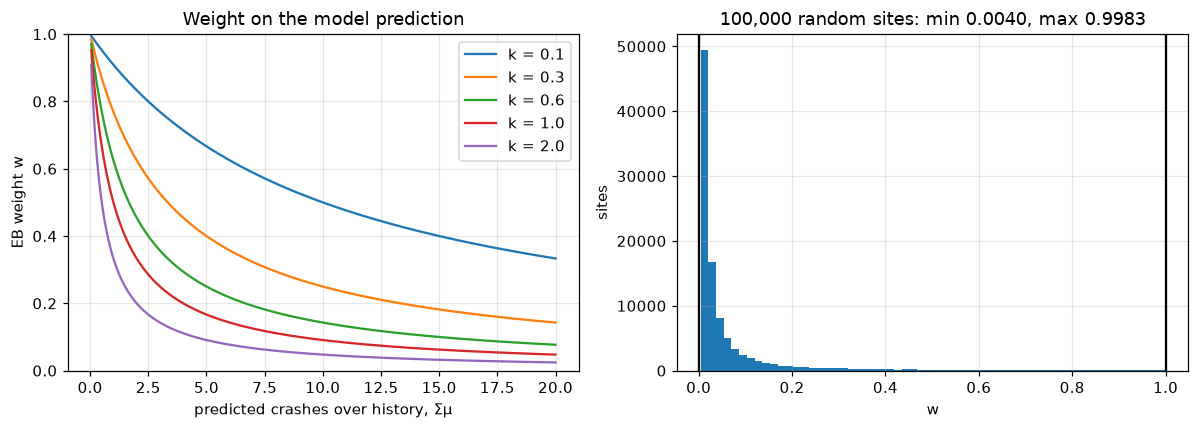

In [4]:
rng = np.random.default_rng(0)
w_rand = eb_weight(rng.uniform(0.01, 50, 100_000), rng.uniform(0.01, 5, 100_000))
assert np.all((w_rand > 0) & (w_rand < 1))

# n_eb always lies between the prediction and the observation
mu_r = rng.uniform(0.1, 20, 10_000)
obs_r = rng.poisson(rng.uniform(0, 30, 10_000))
n_eb_r = eb_estimate(mu_r, obs_r, 0.8).expected
assert np.all(n_eb_r >= np.minimum(mu_r, obs_r) - 1e-12)
assert np.all(n_eb_r <= np.maximum(mu_r, obs_r) + 1e-12)

# monotone in sum_mu, and per-site (length-scaled) k is accepted
assert np.all(np.diff(eb_weight(np.linspace(0.1, 50, 500), 0.5)) < 0)
k_len = 0.236 / np.array([0.1, 0.2])
assert np.allclose(eb_weight([1.0, 1.0], k_len), 1 / (1 + k_len))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
grid = np.linspace(0.05, 20, 300)
for k in [0.1, 0.3, 0.6, 1.0, 2.0]:
    a1.plot(grid, eb_weight(grid, k), label=f"k = {k}")
a1.set(xlabel="predicted crashes over history, Σμ", ylabel="EB weight w", ylim=(0, 1),
       title="Weight on the model prediction")
a1.legend()
a2.hist(w_rand, bins=60, color="tab:blue")
a2.axvline(0, color="k"); a2.axvline(1, color="k")
a2.set(xlabel="w", ylabel="sites", title=f"100,000 random sites: min {w_rand.min():.4f}, max {w_rand.max():.4f}")
plt.tight_layout(); plt.show()

### 2.3 Invalid inputs are rejected

Each row should raise `ValueError` before any weight is computed.

In [5]:
bad_inputs = {
    "zero prediction":       dict(sum_mu=[0.0], sum_observed=[1], k=0.5),
    "zero k":                dict(sum_mu=[1.0], sum_observed=[1], k=0.0),
    "negative count":        dict(sum_mu=[1.0], sum_observed=[-1], k=0.5),
    "fractional count":      dict(sum_mu=[1.0], sum_observed=[1.5], k=0.5),
    "NaN prediction":        dict(sum_mu=[np.nan], sum_observed=[1], k=0.5),
    "length mismatch":       dict(sum_mu=[1.0, 2.0], sum_observed=[1], k=0.5),
}
rows = []
for name, kwargs in bad_inputs.items():
    try:
        eb_estimate(**kwargs)
        rows.append((name, "accepted", ""))
    except ValueError as e:
        rows.append((name, "rejected", str(e)))
rejections = pd.DataFrame(rows, columns=["case", "result", "message"])
assert (rejections.result == "rejected").all()
rejections

,case,result,message
0,zero prediction,rejected,sum_mu must be finite and greater than 0
1,zero k,rejected,k must be finite and greater than 0
2,negative count,rejected,sum_observed must be non-negative whole-number...
3,fractional count,rejected,sum_observed must be non-negative whole-number...
4,NaN prediction,rejected,sum_mu must be finite and greater than 0
5,length mismatch,rejected,"sum_mu has shape (2,) but sum_observed has sha..."


### 2.4 `estimate_k` recovers a known overdispersion

Simulate 20,000 sites at several true k values and fit k back with the predictions held fixed. The profile likelihood on the right shows a single clear minimum at the true value.

,k_true,k_estimated,relative_error
0,0.10,0.1033,0.0332
1,0.25,0.2475,-0.0100
2,0.60,0.6009,0.0014
3,1.00,1.0185,0.0185
4,2.00,2.0172,0.0086


Poisson data: k = 0.00530   under-dispersed data: k = 0.00010 (warned)


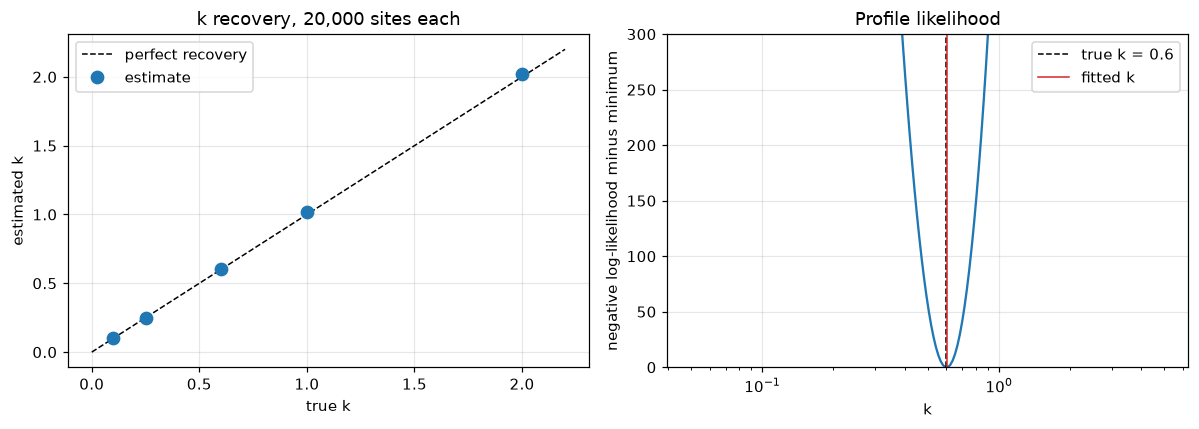

In [6]:
rows = []
for i, k_true in enumerate([0.1, 0.25, 0.6, 1.0, 2.0]):
    y, mu = simulate_site_totals(k_true, 20_000, seed=10 + i)
    k_hat = estimate_k(y, mu)
    rows.append((k_true, k_hat, (k_hat - k_true) / k_true))
k_table = pd.DataFrame(rows, columns=["k_true", "k_estimated", "relative_error"])
assert (k_table.relative_error.abs() < 0.10).all()

# Poisson data (k = 0) should land near zero; under-dispersed data should hit the bound and warn
y0, mu0 = simulate_site_totals(0, 5_000, seed=2)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    k_pois = estimate_k(y0, mu0)
assert k_pois < 0.02
mu_u = np.random.default_rng(4).uniform(0.5, 6.0, 1_000)
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    k_under = estimate_k(np.round(mu_u), mu_u)
assert any("no overdispersion" in str(c.message) for c in caught)
assert np.isclose(k_under, K_BOUNDS[0], rtol=0.01)
display(k_table)
print(f"Poisson data: k = {k_pois:.5f}   under-dispersed data: k = {k_under:.5f} (warned)")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
a1.plot([0, 2.2], [0, 2.2], "k--", lw=1, label="perfect recovery")
a1.plot(k_table.k_true, k_table.k_estimated, "o", ms=8, label="estimate")
a1.set(xlabel="true k", ylabel="estimated k", title="k recovery, 20,000 sites each")
a1.legend()
y6, mu6 = simulate_site_totals(0.6, 20_000, seed=12)
ks = np.exp(np.linspace(np.log(0.05), np.log(5), 200))
nll = [_nb_neg_log_likelihood(np.log(k), y6.astype(float), mu6) for k in ks]
a2.plot(ks, np.array(nll) - min(nll))
a2.axvline(0.6, color="k", ls="--", lw=1, label="true k = 0.6")
a2.axvline(estimate_k(y6, mu6), color="tab:red", lw=1, label="fitted k")
a2.set(xscale="log", xlabel="k", ylabel="negative log-likelihood minus minimum",
       title="Profile likelihood", ylim=(0, 300))
a2.legend()
plt.tight_layout(); plt.show()

## 3. Synthetic demonstration: does EB fix regression to the mean?

This mimics the backtest design on fake data. 5,000 sites each get a true crash rate (model prediction mu times a gamma "site effect" with k = 0.6). We draw a history window (stand-in for the training years) and an independent future window of the same length (stand-in for 2023 to 2025), then compare three ways to predict the future from the history:

- **Raw count:** the history total (what a count-based HIN does).
- **Model only:** mu, ignoring the site's history.
- **EB:** the blend, with k fitted from the history alone.

The future window is never used to fit anything.

In [7]:
rng = np.random.default_rng(42)
n_sites, k_sim = 5_000, 0.6
mu_s = rng.lognormal(mean=0.5, sigma=0.7, size=n_sites)      # model prediction for the window
true_rate = rng.gamma(shape=1 / k_sim, scale=k_sim * mu_s)  # what the site really averages
history = rng.poisson(true_rate)
future = rng.poisson(true_rate)

k_fit = estimate_k(history, mu_s)
eb_s = eb_estimate(mu_s, history, k_fit)
est = {"Raw count": history.astype(float), "Model only": mu_s, "EB": eb_s.expected}

def capture(score, share=0.11):
    """Share of future crashes on the top `share` of sites by score (ties broken by site order)."""
    top = np.argsort(-score, kind="stable")[: int(share * n_sites)]
    return future[top].sum() / future.sum()

ideal = capture(true_rate)
summary = pd.DataFrame({
    "MSE vs true rate": {n: np.mean((e - true_rate) ** 2) for n, e in est.items()},
    "MSE vs future count": {n: np.mean((e - future) ** 2) for n, e in est.items()},
    "Future crashes captured by top 11%": {n: capture(e) for n, e in est.items()},
})
summary.loc["Oracle (true rate)"] = [0.0, np.mean((true_rate - future) ** 2), ideal]
print(f"k fitted from history: {k_fit:.3f} (true {k_sim})")
assert abs(k_fit - k_sim) < 0.1
assert summary.loc["EB", "MSE vs true rate"] < summary.loc["Raw count", "MSE vs true rate"]
assert summary.loc["EB", "MSE vs true rate"] < summary.loc["Model only", "MSE vs true rate"]
assert summary.loc["EB", "Future crashes captured by top 11%"] >= summary.loc["Raw count", "Future crashes captured by top 11%"]
summary.style.format({"MSE vs true rate": "{:.3f}", "MSE vs future count": "{:.3f}",
                      "Future crashes captured by top 11%": "{:.1%}"})

k fitted from history: 0.618 (true 0.6)


,MSE vs true rate,MSE vs future count,Future crashes captured by top 11%
Raw count,2.164,4.164,37.3%
Model only,4.526,6.620,31.1%
EB,1.262,3.269,38.3%
Oracle (true rate),0.000,2.095,41.1%


### 3.1 Regression to the mean, shown directly

Group sites by their history count. Sites with a high history count average far fewer crashes in the future window (the raw count overshoots), while the EB estimate tracks the future average closely across the whole range.

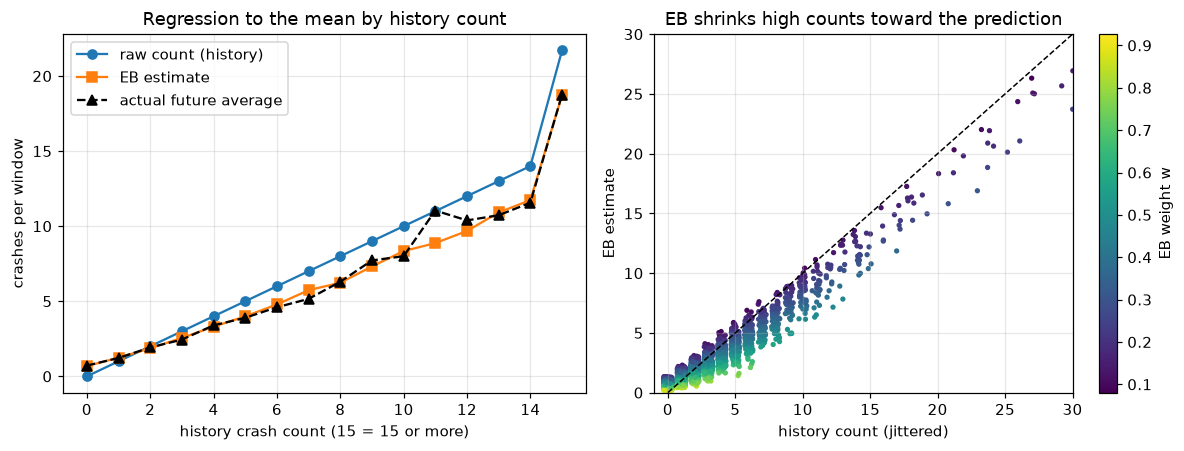

,sites,raw,eb,future
bin,,,,
0,1696,0.0,0.69,0.72
1,1164,1.0,1.24,1.22
2,764,2.0,1.87,1.92
3,436,3.0,2.56,2.45
4,291,4.0,3.31,3.40
5,189,5.0,3.99,3.90
6,128,6.0,4.79,4.60
7,82,7.0,5.74,5.16
8,57,8.0,6.23,6.30


In [8]:
df = pd.DataFrame({"history": history, "future": future, "eb": eb_s.expected,
                   "w": eb_s.weight, "mu": mu_s})
df["bin"] = df.history.clip(upper=15)
g = df.groupby("bin").agg(sites=("future", "size"), raw=("history", "mean"),
                          eb=("eb", "mean"), future=("future", "mean"))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2))
a1.plot(g.index, g.raw, "o-", label="raw count (history)")
a1.plot(g.index, g.eb, "s-", label="EB estimate")
a1.plot(g.index, g.future, "k^--", label="actual future average")
a1.set(xlabel="history crash count (15 = 15 or more)", ylabel="crashes per window",
       title="Regression to the mean by history count")
a1.legend()
sc = a2.scatter(df.history + rng.uniform(-0.3, 0.3, n_sites), df.eb, c=df.w, s=6, cmap="viridis")
a2.plot([0, 30], [0, 30], "k--", lw=1)
a2.set(xlim=(-1, 30), ylim=(0, 30), xlabel="history count (jittered)", ylabel="EB estimate",
       title="EB shrinks high counts toward the prediction")
plt.colorbar(sc, ax=a2, label="EB weight w")
plt.tight_layout(); plt.show()
g.round(2)

### 3.2 Hotspot ranking: who gets flagged

The top 11% of sites by raw count and by EB overlap heavily but not fully. The sites only the raw count flags are the "unlucky years" sites; the table shows how many future crashes each group actually had.

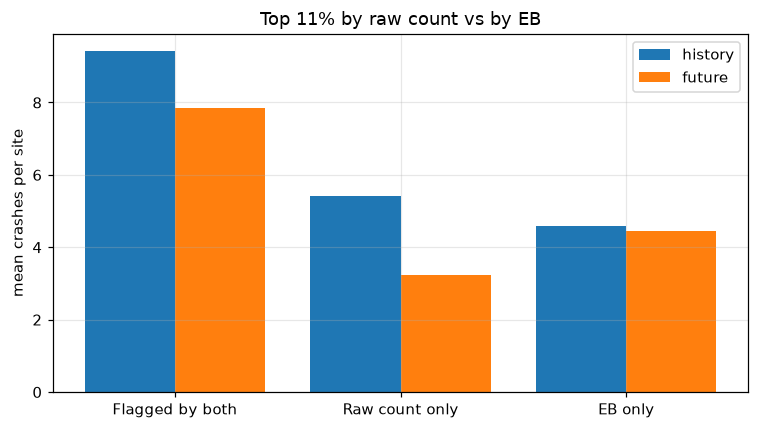

,sites,mean history count,mean future count,mean true rate
Flagged by both,463.0,9.42,7.86,7.83
Raw count only,87.0,5.43,3.24,3.32
EB only,87.0,4.59,4.46,4.64


In [9]:
n_top = int(0.11 * n_sites)
top_raw = set(np.argsort(-history, kind="stable")[:n_top])
top_eb = set(np.argsort(-eb_s.expected, kind="stable")[:n_top])
groups = {"Flagged by both": top_raw & top_eb,
          "Raw count only": top_raw - top_eb,
          "EB only": top_eb - top_raw}
flag_table = pd.DataFrame({
    name: {"sites": len(ids),
           "mean history count": history[list(ids)].mean(),
           "mean future count": future[list(ids)].mean(),
           "mean true rate": true_rate[list(ids)].mean()}
    for name, ids in groups.items()}).T
assert flag_table.loc["EB only", "mean true rate"] > flag_table.loc["Raw count only", "mean true rate"]

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(flag_table))
ax.bar(x - 0.2, flag_table["mean history count"], 0.4, label="history")
ax.bar(x + 0.2, flag_table["mean future count"], 0.4, label="future")
ax.set(xticks=x, xticklabels=flag_table.index, ylabel="mean crashes per site",
       title="Top 11% by raw count vs by EB")
ax.legend(); plt.tight_layout(); plt.show()
flag_table.round(2)

## 4. Summary

| Check | Source | Result |
|---|---|---|
| Toy hand-check matches the formula | EVP Table 8, FSR 3.2.1.7 | Asserted in 2.1 |
| Weights strictly in (0, 1) | EVP Table 8 | Asserted in 2.2 on 100,000 random sites |
| n_EB lies between prediction and observation; per-site k accepted | Module design | Asserted in 2.2 |
| Bad inputs rejected | Module design | Asserted in 2.3 |
| k recovered within 10% on simulated data; warns when no overdispersion | Module design | Asserted in 2.4 |
| EB beats raw counts and model-only on synthetic data | Illustration only | Asserted in 3 and 3.2 |

All of this is synthetic. The real test is the frozen A/B/C backtest on 2023 to 2025 College Station crashes (FSR 3.2.1.10), which still needs `nb_spf.py`, `ml_risk.py`, `ranking.py`, and `backtest.py`.